In [ ]:
pip install -q "rapidocr-onnxruntime" "docling"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.3/70.3 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.9/14.9 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.7/604.7 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.7/18.7 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 257.9/257.9 kB 14.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.0/94.0 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 81.6 MB/s eta 0:00:00
   ━━━━

In [ ]:
import os
os.environ["RAPIDOCR_ENGINE"] = "onnxruntime"

from docling.document_converter import DocumentConverter
source = "/content/mrag-research-paper"
converter = DocumentConverter()
doc = converter.convert(source).document

[INFO] 2026-06-24 21:56:22,135 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-06-24 21:56:22,180 [RapidOCR] download_file.py:60: File exists and is valid: /usr/local/lib/python3.12/dist-packages/rapidocr/models/PP-OCRv6_det_small.onnx
[INFO] 2026-06-24 21:56:22,182 [RapidOCR] main.py:63: Using /usr/local/lib/python3.12/dist-packages/rapidocr/models/PP-OCRv6_det_small.onnx
[INFO] 2026-06-24 21:56:22,338 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-06-24 21:56:22,344 [RapidOCR] download_file.py:60: File exists and is valid: /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-06-24 21:56:22,345 [RapidOCR] main.py:63: Using /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_ppocr_mobile_v2.0_cls_mobile.onnx
[INFO] 2026-06-24 21:56:22,416 [RapidOCR] base.py:23: Using engine_name: onnxruntime
[INFO] 2026-06-24 21:56:22,508 [RapidOCR] download_file.py:60: File exists and is valid: /usr/local/l

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

In [ ]:
import json
import hashlib
from pathlib import Path

from docling_core.transforms.chunker import HierarchicalChunker

# Create output directory
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Chunk document
chunker = HierarchicalChunker()
chunks = [chunk.text for chunk in chunker.chunk(doc)]

# Create JSON structure
chunk_json = {}

for chunk in chunks:
    chunk_hash = hashlib.sha256(
        chunk.encode("utf-8")
    ).hexdigest()

    chunk_json[chunk_hash] = chunk

# Save JSON
json_path = output_dir / "chunks.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(
        chunk_json,
        f,
        ensure_ascii=False,
        indent=2
    )

print(f"Saved {len(chunks)} chunks to {json_path}")

Saved 129 chunks to output/chunks.json


In [ ]:
pip install -q PyMuPDF ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.4 MB/s eta 0:00:00


In [ ]:
import os
import json
import fitz
from PIL import Image
from ultralytics import YOLO

# ─── CONFIG ───────────────────────────────────────────────
INPUT_FILE    = "/content/mrag-research-paper"
OUTPUT_DIR    = "output/images"
JSON_FILE     = "output/image_text.json"
MODEL_PATH    = "/content/yolov8s-doclaynet.pt"
DPI           = 200
CONFIDENCE    = 0.5
VICINITY      = 50    # PDF units — how far "nearby" means
# ──────────────────────────────────────────────────────────

FIGURE_LABELS = {"picture", "figure"}

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs("output", exist_ok=True)

model = YOLO(MODEL_PATH)

doc   = fitz.open(INPUT_FILE)
zoom  = DPI / 72
mat   = fitz.Matrix(zoom, zoom)
total = 0

result_json = {}  # { image_path: nearby_text }

for page_num in range(len(doc)):
    page = doc[page_num]
    pix  = page.get_pixmap(matrix=mat)
    page_image = Image.frombytes("RGB", [pix.width, pix.height], pix.samples)

    results = model(page_image, conf=CONFIDENCE)[0]

    fig_count = 0
    for box, cls, conf in zip(results.boxes.xyxy, results.boxes.cls, results.boxes.conf):
        label = model.names[int(cls)].lower()
        if label not in FIGURE_LABELS:
            continue

        # ── Save image ──────────────────────────────────────
        x1, y1, x2, y2 = [int(c) for c in box]
        cropped  = page_image.crop((x1, y1, x2, y2))
        filename = f"page{page_num + 1}_figure{fig_count + 1}.png"
        img_path = os.path.join(OUTPUT_DIR, filename)
        cropped.save(img_path)

        # ── Get nearby text ──────────────────────────────────
        # Convert pixel bbox back to PDF units for text search
        pdf_x1 = x1 / zoom
        pdf_y1 = y1 / zoom
        pdf_x2 = x2 / zoom
        pdf_y2 = y2 / zoom

        # Expand the box by VICINITY to capture surrounding text
        search_rect = fitz.Rect(
            pdf_x1 - VICINITY,
            pdf_y1 - VICINITY,
            pdf_x2 + VICINITY,
            pdf_y2 + VICINITY
        )

        # Extract text only within that expanded region
        nearby_text = page.get_text("text", clip=search_rect).strip()

        # ── Store in JSON ────────────────────────────────────
        result_json[img_path] = nearby_text

        print(f"  Saved : {filename}  (conf: {conf:.2f})")
        print(f"  Text  : {nearby_text[:80]}{'...' if len(nearby_text) > 80 else ''}")

        fig_count += 1
        total += 1

    print(f"Page {page_num + 1}: {fig_count} figure(s) found\n")

doc.close()

# ── Write JSON ───────────────────────────────────────────
with open(JSON_FILE, "w", encoding="utf-8") as f:
    json.dump(result_json, f, indent=4, ensure_ascii=False)

print(f"[✓] Done! {total} images saved to : {OUTPUT_DIR}/")
print(f"[✓] JSON saved to                 : {JSON_FILE}")


0: 1024x800 1 Page-footer, 5 Section-headers, 15 Texts, 1 Title, 1232.8ms
Speed: 11.0ms preprocess, 1232.8ms inference, 14.7ms postprocess per image at shape (1, 3, 1024, 800)
Page 1: 0 figure(s) found


0: 1024x800 1 List-item, 1 Page-footer, 1 Page-header, 1 Picture, 8 Texts, 1185.6ms
Speed: 8.5ms preprocess, 1185.6ms inference, 1.3ms postprocess per image at shape (1, 3, 1024, 800)
  Saved : page2_figure1.png  (conf: 0.94)
  Text  : MM ’25, October 27–31, 2025, Dublin, Ireland
Figure 1: Comparison of (𝑎) single-...
Page 2: 1 figure(s) found


0: 1024x800 1 Formula, 3 List-items, 1 Page-footer, 5 Section-headers, 10 Texts, 1199.9ms
Speed: 9.0ms preprocess, 1199.9ms inference, 1.2ms postprocess per image at shape (1, 3, 1024, 800)
Page 3: 0 figure(s) found


0: 1024x800 1 Page-footer, 1 Page-header, 1 Picture, 1 Section-header, 11 Texts, 1223.6ms
Speed: 8.3ms preprocess, 1223.6ms inference, 1.3ms postprocess per image at shape (1, 3, 1024, 800)
  Saved : page4_figure1.png  (conf: 0.9

In [ ]:
pip install -q groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 3.7 MB/s eta 0:00:00


In [ ]:
import os
import json
import hashlib
from groq import Groq

# ─── CONFIG ───────────────────────────────────────────────
INPUT_JSON  = "output/image_text.json"
OUTPUT_JSON = "output/image_descriptions.json"
client = Groq(api_key="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")
# ──────────────────────────────────────────────────────────

def image_to_base64_for_groq(image_path):
    import base64
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

def sha256_hash(image_path):
    with open(image_path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

def generate_description(image_base64, nearby_text):
    prompt = f"""
You are extracting information from a PDF.
Nearby text:
{nearby_text}
Task:
Generate a concise, information-dense description of the image.
Use nearby text only when relevant.
Return only the description.
"""
    completion = client.chat.completions.create(
        model="meta-llama/llama-4-scout-17b-16e-instruct",
        messages=[
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {
                        "type": "image_url",
                        "image_url": {"url": f"data:image/jpeg;base64,{image_base64}"},
                    },
                ],
            }
        ],
        temperature=0.2,
        max_completion_tokens=300,
    )
    return completion.choices[0].message.content

# ─── MAIN ─────────────────────────────────────────────────
with open(INPUT_JSON, "r") as f:
    image_text = json.load(f)

output = {}

for img_path, nearby_text in image_text.items():
    if not os.path.exists(img_path):
        print(f"  Skipping (not found): {img_path}")
        continue

    print(f"Processing: {img_path}")

    b64         = image_to_base64_for_groq(img_path)   # only for API call
    sha         = sha256_hash(img_path)
    description = generate_description(b64, nearby_text)

    output[sha] = [img_path, description]              # path instead of base64
    print(f"  Hash : {sha[:20]}...")
    print(f"  Desc : {description[:80]}...")

with open(OUTPUT_JSON, "w", encoding="utf-8") as f:
    json.dump(output, f, indent=4, ensure_ascii=False)

print(f"\n[✓] Done! Saved to: {OUTPUT_JSON}")

Processing: output/images/page2_figure1.png
  Hash : 8ceaf231aa453c62f7c7...
  Desc : The image presents a comparison between two types of RAG (Retrieval-Augmented Ge...
Processing: output/images/page4_figure1.png
  Hash : ff24611adb52c958332e...
  Desc : The image illustrates a multi-agent, multi-modal framework called HM-RAG, which ...
Processing: output/images/page8_figure1.png
  Hash : c75cdee6206330427c4e...
  Desc : A map of the eastern United States with one highlighted colony in dark green, lo...

[✓] Done! Saved to: output/image_descriptions.json


In [ ]:
!pip install -q chromadb open-clip-torch torch torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.3 MB/s eta 0:00:00


In [ ]:
import json
import chromadb
import torch
import open_clip
from pathlib import Path

# ─── PATHS ─────────────────────────────
chroma_path = Path("chroma_db")
chunks_path = Path("output/chunks.json")

# ─── LOAD CHUNKS ───────────────────────
with open(chunks_path, "r", encoding="utf-8") as f:
    chunk_json = json.load(f)

chunk_ids = list(chunk_json.keys())
chunk_texts = list(chunk_json.values())

print(f"Loaded {len(chunk_ids)} chunks")

# ─── LOAD CLIP ─────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"

model, _, _ = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

model = model.to(device)
model.eval()

# ─── EMBEDDING FUNCTION ────────────────
def embed_texts(texts, batch_size=64):
    all_embeddings = []

    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]

            tokens = tokenizer(batch).to(device)

            embeddings = model.encode_text(tokens)
            embeddings = embeddings / embeddings.norm(dim=-1, keepdim=True)

            all_embeddings.extend(
                embeddings.cpu().numpy().tolist()
            )

    return all_embeddings

# ─── CREATE CHROMADB ───────────────────
client = chromadb.PersistentClient(path=str(chroma_path))

collection_name = "text-only"

try:
    client.delete_collection(collection_name)
except:
    pass

collection = client.create_collection(
    name=collection_name
)

# ─── GENERATE EMBEDDINGS ───────────────
embeddings = embed_texts(chunk_texts)

# ─── STORE IN CHROMA ───────────────────
collection.add(
    ids=chunk_ids,
    documents=chunk_texts,
    embeddings=embeddings
)

print(f"[✓] Stored {len(chunk_ids)} text chunks in ChromaDB")
print(f"[✓] Collection: {collection_name}")

Loaded 116 chunks


/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


[✓] Stored 116 text chunks in ChromaDB
[✓] Collection: text-only


In [ ]:
import json
import chromadb
import torch
import open_clip
from PIL import Image
from pathlib import Path

# ─── PATHS ─────────────────────────────
IMAGE_DESC_PATH = "output/image_descriptions.json"
CHROMA_PATH = "chroma_db"

# ─── LOAD DATA ─────────────────────────
with open(IMAGE_DESC_PATH, "r", encoding="utf-8") as f:
    image_data = json.load(f)

# ─── LOAD CLIP ─────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"

model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai"
)

model = model.to(device)
model.eval()

# ─── IMAGE EMBEDDING FUNCTION ──────────
def get_image_embedding(image_path):
    image = preprocess(
        Image.open(image_path).convert("RGB")
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        emb = model.encode_image(image)
        emb = emb / emb.norm(dim=-1, keepdim=True)

    return emb.cpu().numpy()[0].tolist()

# ─── CHROMADB INIT ─────────────────────
client = chromadb.PersistentClient(path=CHROMA_PATH)

collection_name = "image-only"

try:
    client.delete_collection(collection_name)
except:
    pass

image_collection = client.create_collection(
    name=collection_name
)

# ─── BUILD RECORDS ─────────────────────
ids = []
embeddings = []
documents = []
metadatas = []

for img_hash, value in image_data.items():

    img_path = value[0]
    description = value[1]

    if not Path(img_path).exists():
        print(f"Skipping missing: {img_path}")
        continue

    print(f"Processing: {img_path}")

    emb = get_image_embedding(img_path)

    ids.append(img_hash)
    embeddings.append(emb)

    documents.append(description)

    metadatas.append({
        "image_hash": img_hash,
        "image_path": img_path,
        "description": description
    })

# ─── STORE ─────────────────────────────
image_collection.add(
    ids=ids,
    embeddings=embeddings,
    documents=documents,
    metadatas=metadatas
)

print(f"\n[✓] Stored {len(ids)} images in 'image-only'")

Processing: output/images/page2_figure1.png
Processing: output/images/page4_figure1.png
Processing: output/images/page8_figure1.png

[✓] Stored 3 images in 'image-only'


In [ ]:
!pip install -q networkx

In [ ]:
import json
import numpy as np
import torch
import open_clip
import chromadb
import networkx as nx

from PIL import Image
from pathlib import Path

# ─── PATHS ─────────────────────────────
CHUNKS_PATH = Path("output/chunks.json")
IMAGES_PATH = Path("output/image_descriptions.json")
CHROMA_PATH = "chroma_db"

# ─── LOAD DATA ─────────────────────────
with open(CHUNKS_PATH, "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

with open(IMAGES_PATH, "r", encoding="utf-8") as f:
    images_json = json.load(f)

text_ids = list(chunks_json.keys())
text_chunks = list(chunks_json.values())

image_ids = list(images_json.keys())
image_paths = [images_json[i][0] for i in image_ids]
image_descs = [images_json[i][1] for i in image_ids]

# ─── CLIP MODEL ────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"

model, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    quick_gelu=True
)

tokenizer = open_clip.get_tokenizer("ViT-B-32")

model = model.to(device)
model.eval()

# ─── HELPERS ───────────────────────────
def normalize(x):
    return x / np.linalg.norm(x, axis=-1, keepdims=True)

def embed_texts(texts, batch_size=64):
    all_embs = []

    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            tokens = tokenizer(batch).to(device)

            emb = model.encode_text(tokens)
            emb = emb / emb.norm(dim=-1, keepdim=True)

            all_embs.append(emb.cpu().numpy())

    return np.vstack(all_embs)

def embed_image(image_path):
    image = preprocess(
        Image.open(image_path).convert("RGB")
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        emb = model.encode_image(image)
        emb = emb / emb.norm(dim=-1, keepdim=True)

    return emb.cpu().numpy()[0]

print("Setup complete")
print("Text chunks:", len(text_ids))
print("Images:", len(image_ids))

Setup complete
Text chunks: 116
Images: 3


In [ ]:
def process_early_fusion_community(
    community,
    text_embs,
    image_desc_embs,
    similarity_matrix,
    early_threshold=0.75,
    collection_name="early-fusion"
):
    client = chromadb.PersistentClient(path=CHROMA_PATH)

    collection = client.get_or_create_collection(
        name=collection_name
    )

    ids, embeddings, documents, metadatas = [], [], [], []

    community_text_nodes = [n for n in community if n.startswith("text_")]
    community_image_nodes = [n for n in community if n.startswith("image_")]

    for t_node in community_text_nodes:
        t_idx = int(t_node.replace("text_", ""))
        text_id = text_ids[t_idx]
        text_chunk = text_chunks[t_idx]

        for i_node in community_image_nodes:
            i_idx = int(i_node.replace("image_", ""))
            image_id = image_ids[i_idx]
            image_desc = image_descs[i_idx]
            image_path = image_paths[i_idx]

            sim = similarity_matrix[t_idx][i_idx]

            if sim >= early_threshold:
                fused_text = text_chunk + "\n\n" + image_desc
                fused_id = f"{text_id}_{image_id}"

                fused_emb = embed_texts([fused_text])[0]

                ids.append(fused_id)
                embeddings.append(fused_emb.tolist())
                documents.append(fused_text)

                metadatas.append({
                    "fusion_type": "early",
                    "text_id": text_id,
                    "image_id": image_id,
                    "image_path": image_path,
                    "similarity": float(sim)
                })

    if ids:
        collection.upsert(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )

    return len(ids)

In [ ]:
def process_late_fusion_community(
    community,
    text_embs,
    image_desc_embs,
    similarity_matrix,
    late_min_threshold=0.45,
    late_max_threshold=0.75,
    top_k=2,
    collection_name="late-fusion"
):
    client = chromadb.PersistentClient(path=CHROMA_PATH)

    collection = client.get_or_create_collection(
        name=collection_name
    )

    ids, embeddings, documents, metadatas = [], [], [], []

    community_text_nodes = [n for n in community if n.startswith("text_")]
    community_image_nodes = [n for n in community if n.startswith("image_")]

    for i_node in community_image_nodes:
        i_idx = int(i_node.replace("image_", ""))
        image_id = image_ids[i_idx]
        image_path = image_paths[i_idx]
        image_desc = image_descs[i_idx]

        if not Path(image_path).exists():
            continue

        candidate_texts = []

        for t_node in community_text_nodes:
            t_idx = int(t_node.replace("text_", ""))
            sim = similarity_matrix[t_idx][i_idx]

            if late_min_threshold <= sim < late_max_threshold:
                candidate_texts.append((t_idx, sim))

        candidate_texts = sorted(
            candidate_texts,
            key=lambda x: x[1],
            reverse=True
        )[:top_k]

        if not candidate_texts:
            continue

        image_emb = embed_image(image_path)

        for t_idx, sim in candidate_texts:
            text_id = text_ids[t_idx]
            text_chunk = text_chunks[t_idx]
            text_emb = text_embs[t_idx]

            fused_emb = 0.5 * image_emb + 0.5 * text_emb
            fused_emb = fused_emb / np.linalg.norm(fused_emb)

            fused_id = f"{image_id}_{text_id}"

            ids.append(fused_id)
            embeddings.append(fused_emb.tolist())

            documents.append(
                f"IMAGE DESCRIPTION:\n{image_desc}\n\nTEXT CHUNK:\n{text_chunk}"
            )

            metadatas.append({
                "fusion_type": "late",
                "text_id": text_id,
                "image_id": image_id,
                "image_path": image_path,
                "similarity": float(sim)
            })

    if ids:
        collection.upsert(
            ids=ids,
            embeddings=embeddings,
            documents=documents,
            metadatas=metadatas
        )

    return len(ids)

In [ ]:
# ─── CREATE TEXT + IMAGE DESCRIPTION EMBEDDINGS ───────────
print("Embedding text chunks...")
text_embs = embed_texts(text_chunks)

print("Embedding image descriptions...")
image_desc_embs = embed_texts(image_descs)

# ─── SIMILARITY MATRIX ─────────────────
similarity_matrix = text_embs @ image_desc_embs.T

# ─── BUILD BIPARTITE GRAPH ─────────────
GRAPH_EDGE_THRESHOLD = 0.40

G = nx.Graph()

for i in range(len(text_ids)):
    G.add_node(f"text_{i}", type="text", real_id=text_ids[i])

for j in range(len(image_ids)):
    G.add_node(f"image_{j}", type="image", real_id=image_ids[j])

for i in range(len(text_ids)):
    for j in range(len(image_ids)):
        sim = similarity_matrix[i][j]

        if sim >= GRAPH_EDGE_THRESHOLD:
            G.add_edge(
                f"text_{i}",
                f"image_{j}",
                weight=float(sim)
            )

print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())

# ─── LOUVAIN COMMUNITIES ───────────────
communities = nx.community.louvain_communities(
    G,
    weight="weight",
    seed=42
)

print("Communities found:", len(communities))

# ─── APPLY EARLY + LATE FUSION ─────────
total_early = 0
total_late = 0

for idx, community in enumerate(communities):
    print(f"\nProcessing community {idx + 1}/{len(communities)}")

    early_count = process_early_fusion_community(
        community=community,
        text_embs=text_embs,
        image_desc_embs=image_desc_embs,
        similarity_matrix=similarity_matrix,
        early_threshold=0.75
    )

    late_count = process_late_fusion_community(
        community=community,
        text_embs=text_embs,
        image_desc_embs=image_desc_embs,
        similarity_matrix=similarity_matrix,
        late_min_threshold=0.45,
        late_max_threshold=0.75,
        top_k=2
    )

    total_early += early_count
    total_late += late_count

    print("Early fused:", early_count)
    print("Late fused :", late_count)

print("\n[✓] Hybrid Fusion complete")
print("[✓] Early fusion records:", total_early)
print("[✓] Late fusion records :", total_late)

Embedding text chunks...
Embedding image descriptions...
Graph nodes: 119
Graph edges: 228
Communities found: 5

Processing community 1/5
Early fused: 0
Late fused : 0

Processing community 2/5
Early fused: 0
Late fused : 0

Processing community 3/5
Early fused: 0
Late fused : 0

Processing community 4/5
Early fused: 25
Late fused : 2

Processing community 5/5
Early fused: 21
Late fused : 2

[✓] Hybrid Fusion complete
[✓] Early fusion records: 46
[✓] Late fusion records : 4


In [ ]:
import torch
import open_clip
import chromadb

# ─── CHROMA DB ─────────────────────────
client = chromadb.PersistentClient(path="chroma_db")

text_col  = client.get_collection("text-only")
image_col = client.get_collection("image-only")
early_col = client.get_collection("early-fusion")
late_col  = client.get_collection("late-fusion")

# ─── CLIP MODEL ────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"

model, _, _ = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    quick_gelu=True
)

model = model.to(device)
model.eval()

tokenizer = open_clip.get_tokenizer("ViT-B-32")

# ─── QUERY EMBEDDING ───────────────────
def get_query_embedding(query):
    with torch.no_grad():
        tokens = tokenizer([query]).to(device)

        emb = model.encode_text(tokens)
        emb = emb / emb.norm(dim=-1, keepdim=True)

    return emb.cpu().numpy()

# ─── SEARCH ────────────────────────────
def search_all_collections(query, k=10):

    q_emb = get_query_embedding(query)

    results = {
        "text": text_col.query(
            query_embeddings=q_emb,
            n_results=k
        ),

        "image": image_col.query(
            query_embeddings=q_emb,
            n_results=k
        ),

        "early": early_col.query(
            query_embeddings=q_emb,
            n_results=k
        ),

        "late": late_col.query(
            query_embeddings=q_emb,
            n_results=k
        )
    }

    return results

# ─── TEST ──────────────────────────────
query = "Explain me Overview of HM-RAG. A multi-agent multi-modal framework."

results = search_all_collections(query)

print("TEXT :", len(results["text"]["ids"][0]))
print("IMAGE:", len(results["image"]["ids"][0]))
print("EARLY:", len(results["early"]["ids"][0]))
print("LATE :", len(results["late"]["ids"][0]))

print("TEXT :", results["text"]["ids"][0])
print("IMAGE:", results["image"]["ids"][0])
print("EARLY:", results["early"]["ids"][0])
print("LATE :", results["late"]["ids"][0])

TEXT : 10
IMAGE: 3
EARLY: 10
LATE : 4
TEXT : ['bc2862ae5d6a3c4f9a80dce7d35d6ecd086d64ad8ce23857cd558545fecd5ebd', 'e3680f4c22d0e3d307d9a45f5ff97f49ac74e6076b24f7f4fd2bdb3d67712ad1', '9a6c4779eceb13ac43aa0ba9166ae99bc2c24119516288a7c4109bcac520c765', '98c5f5f6ddaed13a4f6efee902a20ac96ab3f829cbf19824684ac6dd5bf40a6b', '7ac603ec526cf64e4171e72af06ef7d12c2e3c9eb4cf57c96990cf33f243add1', '78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2', 'ea487d8a334a781d0fba92a123c31f16267afdbbf1569e7ae06b5fe3893b8c8a', '4de5572d564a4b14fb9a736b154232fccfaa4d2ee896871774a85609bb2f93ae', '8867ec3055abd0d3d6ecf12bb9bdaa103dc2f308405e6715f02ec9759c0fd690', '4b7d3384c56029e0b190467d4d394fef8e0b43b043d91a7268514bf177fc913b']
IMAGE: ['8ceaf231aa453c62f7c7b8cace0602d7782a8404e0f2f246980f4ac6c182ca29', 'ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc1eaa8982f3f', 'c75cdee6206330427c4e5832319d03d38036b69cacf1a65fb64e5a24a4c4024d']
EARLY: ['bc2862ae5d6a3c4f9a80dce7d35d6ecd086d64ad8ce23857cd558

In [ ]:
def unify_results(results):

    unified = []

    mapping = {
        "text": "text-only",
        "image": "image-only",
        "early": "early-fusion",
        "late": "late-fusion"
    }

    for collection_name, result in results.items():

        ids = result["ids"][0]
        docs = result["documents"][0]
        metas = result["metadatas"][0]
        dists = result["distances"][0]

        for rank, (id_, doc, meta, dist) in enumerate(
            zip(ids, docs, metas, dists),
            start=1
        ):
            unified.append({
                "id": id_,
                "document": doc,
                "metadata": meta,
                "distance": dist,
                "rank": rank,
                "collection": mapping[collection_name]
            })

    print(f"[✓] Unified {len(unified)} candidates")

    return unified

unified = unify_results(results)

[✓] Unified 27 candidates


In [ ]:
from collections import defaultdict

def reciprocal_rank_fusion(
    unified_results,
    k=60
):

    fused = defaultdict(
        lambda: {
            "rrf_score": 0.0,
            "document": None,
            "metadata": None,
            "sources": []
        }
    )

    for item in unified_results:

        doc_id = item["id"]

        fused[doc_id]["rrf_score"] += 1 / (k + item["rank"])

        fused[doc_id]["document"] = item["document"]
        fused[doc_id]["metadata"] = item["metadata"]

        fused[doc_id]["sources"].append({
            "collection": item["collection"],
            "rank": item["rank"]
        })

    fused = [
        {
            "id": doc_id,
            **values
        }
        for doc_id, values in fused.items()
    ]

    fused.sort(
        key=lambda x: x["rrf_score"],
        reverse=True
    )

    print(f"[✓] RRF fused {len(fused)} candidates")

    return fused

rrf_results = reciprocal_rank_fusion(unified)

[✓] RRF fused 27 candidates


In [ ]:
def deduplicate_candidates(rrf_results):

    seen_docs = set()

    unique = []

    for item in rrf_results:

        doc = item["document"]

        if doc in seen_docs:
            continue

        seen_docs.add(doc)

        unique.append(item)

    print(
        f"[✓] Deduplicated: {len(rrf_results)} → {len(unique)}"
    )

    return unique

unique_results = deduplicate_candidates(rrf_results)

[✓] Deduplicated: 27 → 27


In [ ]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

def rerank_results(
    query,
    candidates,
    top_n=10
):

    pairs = [
        [query, c["document"]]
        for c in candidates
    ]

    scores = reranker.predict(pairs)

    for i, candidate in enumerate(candidates):
        candidate["rerank_score"] = float(scores[i])

    reranked = sorted(
        candidates,
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    reranked = reranked[:top_n]

    print(f"[✓] Top {top_n} reranked")

    return reranked

top_results = rerank_results(
    query,
    unique_results,
    top_n=10
)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[✓] Top 10 reranked


In [ ]:
for rank, item in enumerate(top_results, start=1):

    print("\n" + "="*80)

    print(f"Rank        : {rank}")
    print(f"ID          : {item['id']}")
    print(f"RRF Score   : {item['rrf_score']:.6f}")
    print(f"Rerank Score: {item['rerank_score']:.4f}")

    print(
        f"Sources     : "
        f"{[s['collection'] for s in item['sources']]}"
    )

    print(
        f"Text        : "
        f"{item['document'][:250]}"
    )


Rank        : 1
ID          : 78213b7f0c56872f5ea975babb83da4735bb0601655b34ddfba082b1e217efa2
RRF Score   : 0.015152
Rerank Score: 8.4848
Sources     : ['text-only']
Text        : Figure 2: Overview of HM-RAG. A multi-agent multi-modal framework operates in three stages: First, the Decomposition Agent uses an LLM to rewrite and decompose the question into several sub-queries. Second, the Multi-source Retrieval Agent retrieves 

Rank        : 2
ID          : ff24611adb52c958332e1bc556362ff5c8128f7ee3d0a04ffa1bc1eaa8982f3f_be9c738de15306dd14bedfbb1cf498abf128e005a0554c699c79c699d5308af5
RRF Score   : 0.015873
Rerank Score: 6.7876
Sources     : ['late-fusion']
Text        : IMAGE DESCRIPTION:
The image illustrates a multi-agent, multi-modal framework called HM-RAG, which operates in three stages to answer questions. 

The framework consists of: 
1. A Decomposition Agent that uses an LLM to rewrite and decompose the ques

Rank        : 3
ID          : bc2862ae5d6a3c4f9a80dce7d35d6ecd086d

In [ ]:
import base64
import json
from groq import Groq

# ─── LOAD DATA ─────────────────────────
with open("output/chunks.json", "r", encoding="utf-8") as f:
    text_chunks = json.load(f)

with open("output/image_descriptions.json", "r", encoding="utf-8") as f:
    image_data = json.load(f)

# ─── GROQ ──────────────────────────────
groq_client = Groq(
    api_key="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"
)

# ─── HELPERS ───────────────────────────
def image_to_base64(image_path):
    with open(image_path, "rb") as f:
        return base64.b64encode(
            f.read()
        ).decode("utf-8")


def resolve_doc(result):

    doc_id = result["id"]
    meta = result.get("metadata") or {}

    # text-only
    if not meta:

        return {
            "source": "text",
            "text": text_chunks.get(doc_id, ""),
            "image": None,
            "image_id": None
        }

    # image-only
    if "fusion_type" not in meta:

        img_path = meta["image_path"]

        return {
            "source": "image",
            "text": meta.get("description", ""),
            "image": image_to_base64(img_path),
            "image_id": doc_id
        }

    # early / late fusion
    text_id = meta["text_id"]
    image_id = meta["image_id"]
    img_path = meta["image_path"]

    return {
        "source": meta["fusion_type"],
        "text": text_chunks.get(text_id, ""),
        "image": image_to_base64(img_path),
        "image_id": image_id
    }


def generate_answer(query, top_results):

    content = []

    content.append({
        "type": "text",
        "text":
        f"""
Answer the query using only the retrieved context.

Query:
{query}

Retrieved Context:
"""
    })

    seen_images = set()

    for rank, result in enumerate(top_results, start=1):

        resolved = resolve_doc(result)

        content.append({
            "type": "text",
            "text":
            f"""
Rank: {rank}
Source: {resolved['source']}
Score : {result['rerank_score']:.4f}

{resolved['text']}
"""
        })

        if (
            resolved["image"] is not None
            and resolved["image_id"] not in seen_images
        ):

            seen_images.add(
                resolved["image_id"]
            )

            content.append({
                "type": "image_url",
                "image_url": {
                    "url":
                    f"data:image/png;base64,{resolved['image']}"
                }
            })

    response = groq_client.chat.completions.create(
        model="meta-llama/llama-4-scout-17b-16e-instruct",
        messages=[
            {
                "role": "user",
                "content": content
            }
        ],
        temperature=0.2,
        max_completion_tokens=1500
    )

    return response.choices[0].message.content


# ─── RUN ───────────────────────────────
answer = generate_answer(
    query,
    top_results
)

print("\nGenerated Answer\n")
print(answer)


Generated Answer

Based on the retrieved context, here's an overview of HM-RAG, a multi-agent multi-modal framework:

**Overview of HM-RAG**

HM-RAG (Hierarchical Multi-Agent Retrieval-Augmented Generation) is a novel framework that tackles complex challenges in Retrieval-Augmented Generation (RAG) systems. It features a multi-agent, multi-modal architecture with specialized agents for information extraction and multi-source retrieval.

**Architecture**

The framework consists of three stages:

1. **Decomposition Agent**: Uses a Large Language Model (LLM) to rewrite and decompose a question into several sub-queries.
2. **Multi-source Retrieval Agent**: Retrieves the top-k relevant documents from vector-, graph-, and web-based sources as needed.
3. **Decision Agent**: Provides a voting mechanism and refinement process to generate the final answer.

**Key Features**

* Multi-source plug-and-play retrieval integration for seamless connectivity across diverse data sources
* Expert-guided 

In [ ]:
from sentence_transformers import SentenceTransformer, util
import nltk

nltk.download("punkt_tab")

from nltk.tokenize import sent_tokenize

sent_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

# ─── EXTRACT UNIQUE IMAGES USED ─────────
retrieved_images = {}   # {img_path: description}

for doc in top_results:

    resolved = resolve_doc(doc)

    if (
        resolved.get("image")
        and resolved.get("image_id")
    ):

        img_id = resolved["image_id"]

        if img_id in image_data:

            img_path = image_data[img_id][0]
            img_desc = image_data[img_id][1]

            if img_path not in retrieved_images:
                retrieved_images[img_path] = img_desc

print(
    f"[✓] {len(retrieved_images)} unique images used in answer generation"
)

for path, desc in retrieved_images.items():
    print(
        f"  {path}: {desc[:80]}..."
    )

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[✓] 1 unique images used in answer generation
  output/images/page4_figure1.png: The image illustrates a multi-agent, multi-modal framework called HM-RAG, which ...


In [ ]:
import networkx as nx

# ─── ANSWER SENTENCES ───────────────────
sentences = sent_tokenize(answer)

image_paths = list(
    retrieved_images.keys()
)

image_descs = list(
    retrieved_images.values()
)

# ─── EMBEDDINGS ─────────────────────────
sentence_embeddings = sent_model.encode(
    sentences,
    convert_to_tensor=True
)

image_embeddings = sent_model.encode(
    image_descs,
    convert_to_tensor=True
)

# ─── BUILD BIPARTITE GRAPH ──────────────
G = nx.Graph()

SIMILARITY_THRESHOLD = 0.35

for i, sentence in enumerate(sentences):

    for j, img_path in enumerate(image_paths):

        similarity = util.cos_sim(
            sentence_embeddings[i],
            image_embeddings[j]
        ).item()

        if similarity >= SIMILARITY_THRESHOLD:

            G.add_edge(
                f"s_{i}",
                f"img_{j}",
                weight=similarity
            )

# ─── EDMONDS BLOSSOM ────────────────────
matching = nx.algorithms.matching.max_weight_matching(
    G,
    maxcardinality=False
)

# ─── MAP SENTENCE ↔ IMAGE ───────────────
sentence_to_image = {}

for a, b in matching:

    if a.startswith("s_"):
        s_idx = int(a.split("_")[1])
        img_idx = int(b.split("_")[1])
    else:
        s_idx = int(b.split("_")[1])
        img_idx = int(a.split("_")[1])

    sentence_to_image[s_idx] = image_paths[img_idx]

print(
    f"[✓] Matched {len(sentence_to_image)} sentences to images"
)

[✓] Matched 1 sentences to images


─── Multimodal Answer ───



Based on the retrieved context, here's an overview of HM-RAG, a multi-agent multi-modal framework:

**Overview of HM-RAG**

HM-RAG (Hierarchical Multi-Agent Retrieval-Augmented Generation) is a novel framework that tackles complex challenges in Retrieval-Augmented Generation (RAG) systems.

It features a multi-agent, multi-modal architecture with specialized agents for information extraction and multi-source retrieval.

**Architecture**

The framework consists of three stages:

1.

**Decomposition Agent**: Uses a Large Language Model (LLM) to rewrite and decompose a question into several sub-queries.

...

**Decision Agent**: Provides a voting mechanism and refinement process to generate the final answer.

**Key Features**

* Multi-source plug-and-play retrieval integration for seamless connectivity across diverse data sources
* Expert-guided refinement processes to enhance response quality
* Modularized hierarchical framework for scalable and efficient multimodal retrieval
* Three-tiered architecture with specialized agents for query decomposition, multi-source retrieval, and decision-making

**How it Works**

Given a natural language question and a reference document, HM-RAG retrieves semantically relevant content from the document, integrating it with generative language models to produce answers strictly grounded in the document.

The framework advances multimodal question answering and multi-agent RAG capabilities.

**Benefits**

HM-RAG achieves efficient and contextually relevant responses by combining query decomposition, parallelized information retrieval, and expert-guided answer refinement.

↳ [output/images/page4_figure1.png]


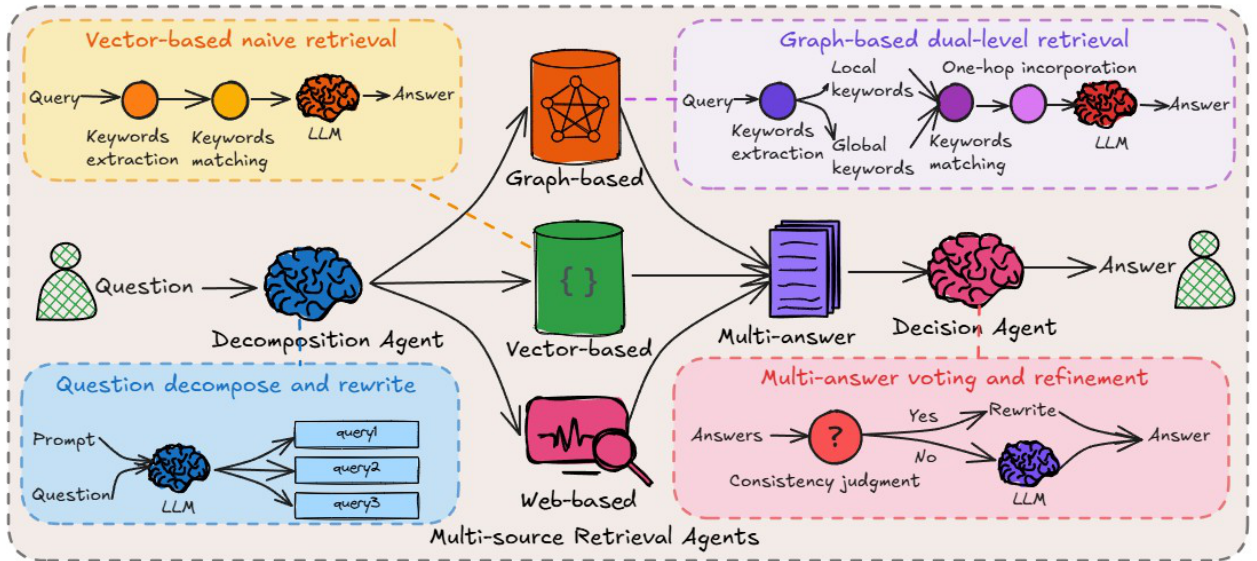

It has attained state-of-the-art performance on benchmark datasets, such as ScienceQA and CrisisMMD.

In [ ]:
from IPython.display import (
    display,
    Image as IPImage,
    Markdown
)

print("─── Multimodal Answer ───\n")

for i, sentence in enumerate(sentences):

    display(
        Markdown(sentence)
    )

    if i in sentence_to_image:

        img_path = sentence_to_image[i]

        print(f"↳ [{img_path}]")

        display(
            IPImage(
                filename=img_path,
                width=500
            )
        )

        print()

In [ ]:
import json
from pathlib import Path
from groq import Groq

# ─── PATHS ──────────────────────────────
chunks_path  = Path("output/chunks.json")
dataset_path = Path("output/eval_dataset_hybridfusion.json")

# ─── LOAD CHUNKS ────────────────────────
with open(chunks_path, "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

# ─── GROQ CLIENT ────────────────────────
client = Groq(api_key="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")

# ─── GENERATE QA PAIR ───────────────────
def generate_qa(chunk_id, chunk_text):

    prompt = f"""
Generate one meaningful evaluation question and its detailed ground-truth answer strictly from the text below.

Return ONLY valid JSON in this format:
{{
  "question": "question here",
  "answer": "answer here"
}}

If the text is too short or uninformative, return:
{{"question": "", "answer": ""}}

Text:
{chunk_text}
"""

    response = client.chat.completions.create(
        model="llama-3.3-70b-versatile",
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        temperature=0.2,
        max_tokens=512
    )

    raw = response.choices[0].message.content.strip()
    data = json.loads(raw)

    if data["question"] and data["answer"]:
        print(f"[✓] {chunk_id[:20]}... → {data['question'][:70]}...")

        return {
            "chunk_id": chunk_id,
            "question": data["question"],
            "ground_truth": data["answer"],
            "chunk_text": chunk_text
        }

    print(f"[–] Skipped {chunk_id[:20]}...")

    return None

# ─── RUN ────────────────────────────────
dataset = {}
chunk_ids = list(chunks_json.keys())

START, END = 50, 90

for chunk_id in chunk_ids[START:END]:

    try:
        result = generate_qa(
            chunk_id,
            chunks_json[chunk_id]
        )

        if result:
            dataset[chunk_id] = result

    except Exception as e:
        print(f"[✗] Error on {chunk_id[:20]}...: {e}")

# ─── SAVE ───────────────────────────────
with open(dataset_path, "w", encoding="utf-8") as f:
    json.dump(
        dataset,
        f,
        ensure_ascii=False,
        indent=4
    )

print(f"\n[✓] Saved {len(dataset)} QA pairs → {dataset_path}")

[✓] bc2862ae5d6a3c4f9a80... → What is the primary function of RAG in the context of HM-RAG, given a ...
[✓] 9bf7853ba5757444a7bc... → What is the primary goal of multimodal data processing in this section...
[✓] f6a82480a124e5da1767... → What approach do conventional entity-centric methods for multimodal kn...
[–] Skipped f55221dda93ddf387e04...
[✓] 46221facb312390eecbf... → What is the primary function of the cross-modal alignment module 𝑓 𝑎𝑙𝑖...
[✓] 78213b7f0c56872f5ea9... → What are the three stages of the HM-RAG multi-agent multi-modal framew...
[✓] 1c78e0cdd924bfe2c6ae... → What are the three phases of the process described in the text?...
[✓] 5bd6c06e65e528fdb040... → How is the multimodal textual knowledge base formed?...
[✓] 0870bf93a769d0197c79... → What does 𝑇 represent in the context of multimodal textual aggregation...
[✓] 4a2f42272530ff011bf9... → What framework is employed for efficient multi-hop reasoning and dynam...
[✓] 3a8ac41a08dd720af44f... → What type of strategy d

In [ ]:
import json
import numpy as np
from pathlib import Path
from sentence_transformers import SentenceTransformer, util, CrossEncoder
import chromadb
import torch
import open_clip
from collections import defaultdict

# ─── LOAD DATA ─────────────────────────
with open("output/eval_dataset_hybridfusion.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

with open("output/chunks.json", "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

# ─── MODELS ────────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model, _, _ = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    quick_gelu=True
)

clip_model = clip_model.to(device)
clip_model.eval()

tokenizer = open_clip.get_tokenizer("ViT-B-32")

reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")
sent_model = SentenceTransformer("all-MiniLM-L6-v2")

# ─── CHROMA COLLECTIONS ────────────────
client = chromadb.PersistentClient(path="chroma_db")

text_col  = client.get_collection("text-only")
image_col = client.get_collection("image-only")
early_col = client.get_collection("early-fusion")
late_col  = client.get_collection("late-fusion")

# ─── CONFIG ────────────────────────────
N = 5
LAMBDA = 1.5
RRF_K = 60

# ─── QUERY EMBEDDING ───────────────────
def get_query_emb(query):
    with torch.no_grad():
        tokens = tokenizer([query]).to(device)
        emb = clip_model.encode_text(tokens)
        emb = emb / emb.norm(dim=-1, keepdim=True)

    return emb.cpu().numpy()

# ─── HYBRID RETRIEVE + RRF + RERANK ─────
def retrieve_top_k(query, n_retrieve=10, n_rerank=N):

    q_emb = get_query_emb(query)

    collection_results = {
        "text-only": text_col.query(query_embeddings=q_emb, n_results=n_retrieve),
        "image-only": image_col.query(query_embeddings=q_emb, n_results=n_retrieve),
        "early-fusion": early_col.query(query_embeddings=q_emb, n_results=n_retrieve),
        "late-fusion": late_col.query(query_embeddings=q_emb, n_results=n_retrieve)
    }

    # ─── UNIFY + RRF ────────────────────
    fused = defaultdict(lambda: {
        "rrf_score": 0.0,
        "document": None,
        "metadata": None,
        "sources": []
    })

    for col_name, res in collection_results.items():

        ids = res["ids"][0]
        docs = res["documents"][0]
        metas = res["metadatas"][0]
        dists = res["distances"][0]

        for rank, (id_, doc, meta, dist) in enumerate(
            zip(ids, docs, metas, dists),
            start=1
        ):
            fused[id_]["rrf_score"] += 1 / (RRF_K + rank)
            fused[id_]["document"] = doc
            fused[id_]["metadata"] = meta or {}
            fused[id_]["sources"].append({
                "collection": col_name,
                "rank": rank,
                "distance": dist
            })

    candidates = [
        {
            "id": id_,
            **data
        }
        for id_, data in fused.items()
    ]

    # ─── DEDUPLICATE BY DOCUMENT TEXT ───
    unique = []
    seen_docs = set()

    for c in sorted(candidates, key=lambda x: x["rrf_score"], reverse=True):
        if c["document"] not in seen_docs:
            seen_docs.add(c["document"])
            unique.append(c)

    # ─── CROSS ENCODER RERANK ───────────
    pairs = [[query, c["document"]] for c in unique]
    scores = reranker.predict(pairs)

    for i, c in enumerate(unique):
        c["rerank_score"] = float(scores[i])

    reranked = sorted(
        unique,
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    return reranked[:n_rerank]

# ─── ID MATCH ──────────────────────────
def id_matches(result, chunk_id):

    doc_id = result["id"]
    meta = result.get("metadata") or {}

    if doc_id == chunk_id:
        return True

    if meta.get("text_id") == chunk_id:
        return True

    if chunk_id in doc_id:
        return True

    return False

# ─── ERROR POINT: PRESENT ──────────────
def error_point_present(k, N, real_emb, top_k_docs):

    normalization = sum(1 / i for i in range(1, N + 1) if i != k)

    if normalization == 0:
        return 0.0

    weighted_sum = 0.0

    for rank, doc in enumerate(top_k_docs, start=1):

        if rank == k:
            continue

        doc_emb = sent_model.encode(
            doc["document"],
            convert_to_tensor=True
        )

        sim = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return (k / N) * (weighted_sum / normalization)

# ─── ERROR POINT: ABSENT ───────────────
def error_point_absent(N, real_emb, top_k_docs):

    normalization = sum(1 / i for i in range(1, N + 1))

    if normalization == 0:
        return LAMBDA

    weighted_sum = 0.0

    for rank, doc in enumerate(top_k_docs, start=1):

        doc_emb = sent_model.encode(
            doc["document"],
            convert_to_tensor=True
        )

        sim = float(util.cos_sim(real_emb, doc_emb)[0][0])
        weighted_sum += sim * (1 / rank)

    return LAMBDA * (weighted_sum / normalization)

# ─── EVALUATE ONE QUESTION ─────────────
def evaluate_question(chunk_id, question, real_chunk_content):

    top_k = retrieve_top_k(question)

    rank_of_real = None

    for rank, result in enumerate(top_k, start=1):
        if id_matches(result, chunk_id):
            rank_of_real = rank
            break

    hit_at_k = int(rank_of_real is not None)
    mrr = (1 / rank_of_real) if rank_of_real else 0.0

    real_emb = sent_model.encode(
        real_chunk_content,
        convert_to_tensor=True
    )

    ep = (
        error_point_present(rank_of_real, N, real_emb, top_k)
        if hit_at_k
        else error_point_absent(N, real_emb, top_k)
    )

    return {
        "chunk_id": chunk_id,
        "question": question,
        "hit_at_k": hit_at_k,
        "rank": rank_of_real,
        "mrr": mrr,
        "error_point": ep
    }

print("[✓] Hybrid Fusion eval functions ready")

/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[✓] Hybrid Fusion eval functions ready


In [ ]:
# ─── RUN EVALUATION ────────────────────
results_per_question = []

for chunk_id, entry in dataset.items():

    question = entry["question"]
    real_chunk = chunks_json.get(chunk_id, "")

    if not real_chunk:
        print(f"[SKIP] {chunk_id[:20]}... not found")
        continue

    print(f"Evaluating: {question[:70]}...")

    result = evaluate_question(
        chunk_id,
        question,
        real_chunk
    )

    results_per_question.append(result)

    print(
        f"  Hit@{N}: {result['hit_at_k']} | "
        f"Rank: {result['rank']} | "
        f"MRR: {result['mrr']:.4f} | "
        f"ErrorPoint: {result['error_point']:.4f}"
    )

# ─── AGGREGATE ─────────────────────────
total = len(results_per_question)

hit_at_k = sum(r["hit_at_k"] for r in results_per_question) / total
mean_mrr = sum(r["mrr"] for r in results_per_question) / total
mean_error_point = sum(r["error_point"] for r in results_per_question) / total

print("\n" + "=" * 60)
print("HYBRID FUSION — RETRIEVAL EVALUATION SUMMARY")
print("=" * 60)
print(f"Total questions evaluated : {total}")
print(f"Hit@{N}                   : {hit_at_k:.4f} ({hit_at_k*100:.1f}%)")
print(f"Mean Reciprocal Rank      : {mean_mrr:.4f}")
print(f"Mean Error Point          : {mean_error_point:.4f} (lower = better)")
print("=" * 60)

# ─── SAVE ──────────────────────────────
eval_output = {
    "summary": {
        "total_questions": total,
        f"hit_at_{N}": round(hit_at_k, 4),
        "mean_mrr": round(mean_mrr, 4),
        "mean_error_point": round(mean_error_point, 4)
    },
    "per_question": results_per_question
}

with open("output/eval_retrieval_hybridfusion.json", "w", encoding="utf-8") as f:
    json.dump(eval_output, f, indent=4, ensure_ascii=False)

print("\n[✓] Saved → output/eval_retrieval_hybridfusion.json")

Evaluating: What is the primary function of RAG in the context of HM-RAG, given a ...
  Hit@5: 1 | Rank: 1 | MRR: 1.0000 | ErrorPoint: 0.1592
Evaluating: What is the primary goal of multimodal data processing in this section...
  Hit@5: 1 | Rank: 1 | MRR: 1.0000 | ErrorPoint: 0.1200
Evaluating: What approach do conventional entity-centric methods for multimodal kn...
  Hit@5: 0 | Rank: None | MRR: 0.0000 | ErrorPoint: 0.7667
Evaluating: What is the primary function of the cross-modal alignment module 𝑓 𝑎𝑙𝑖...
  Hit@5: 0 | Rank: None | MRR: 0.0000 | ErrorPoint: 0.6222
Evaluating: What are the three stages of the HM-RAG multi-agent multi-modal framew...
  Hit@5: 0 | Rank: None | MRR: 0.0000 | ErrorPoint: 1.1917
Evaluating: What are the three phases of the process described in the text?...
  Hit@5: 1 | Rank: 1 | MRR: 1.0000 | ErrorPoint: 0.0897
Evaluating: How is the multimodal textual knowledge base formed?...
  Hit@5: 1 | Rank: 1 | MRR: 1.0000 | ErrorPoint: 0.1240
Evaluating: What does 

In [ ]:
pip install -q bert-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.0 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Q: What is the primary function of RAG in the context of HM-RAG, given a natural la...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

...

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  A5 chunks=1~5 → composite: 0.7847


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  A-Gen → composite: 0.7847

HYBRID FUSION — GENERATION EVALUATION SUMMARY
  A1 avg composite: 0.8008
  A2 avg composite: 0.7713
  A3 avg composite: 0.7896
  A4 avg composite: 0.7957
  A5 avg composite: 0.7957
  A-Gen avg composite: 0.8034

  GT chunk in top5    : 6 / 10
  GT chunk NOT in top5: 4 / 10
  → Retrieval weakness detected


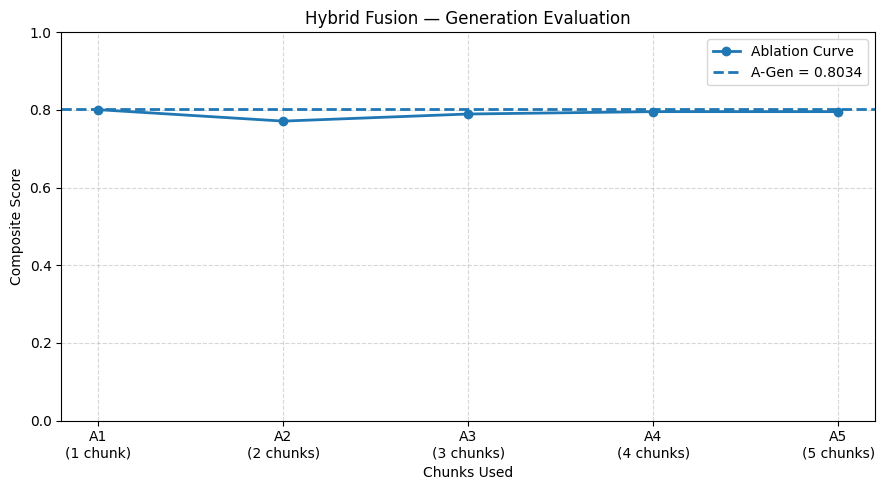


[✓] Plot    → output/generation_eval_hybridfusion.png
[✓] Results → output/generation_eval_hybridfusion.json


In [ ]:
# ============================================================
# HYBRID FUSION — GENERATION EVALUATION
# Metrics: Cosine Similarity, BERTScore, LLM-Judge, Composite
# Framework: Chunk Ablation across Hybrid Retrieval
# ============================================================

!pip install -q bert-score

import json
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

from bert_score import score as bert_score
from sentence_transformers import SentenceTransformer, util, CrossEncoder
from groq import Groq

import chromadb
import torch
import open_clip

# ─── CONFIG ─────────────────────────────
GROQ_API_KEY = "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"
CHROMA_PATH = "chroma_db"

N = 5
RRF_K = 60

# ─── LOAD DATA ──────────────────────────
with open("output/eval_dataset_hybridfusion.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

with open("output/chunks.json", "r", encoding="utf-8") as f:
    chunks_json = json.load(f)

# ─── MODELS ─────────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"

clip_model, _, _ = open_clip.create_model_and_transforms(
    "ViT-B-32",
    pretrained="openai",
    quick_gelu=True
)

clip_model = clip_model.to(device)
clip_model.eval()

tokenizer = open_clip.get_tokenizer("ViT-B-32")

reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")
sent_model = SentenceTransformer("all-MiniLM-L6-v2")
groq_client = Groq(api_key=GROQ_API_KEY)

# ─── CHROMA ─────────────────────────────
client = chromadb.PersistentClient(path=CHROMA_PATH)

text_col  = client.get_collection("text-only")
image_col = client.get_collection("image-only")
early_col = client.get_collection("early-fusion")
late_col  = client.get_collection("late-fusion")

# ─── QUERY EMBEDDING ────────────────────
def get_query_emb(query):
    with torch.no_grad():
        tokens = tokenizer([query]).to(device)
        emb = clip_model.encode_text(tokens)
        emb = emb / emb.norm(dim=-1, keepdim=True)

    return emb.cpu().numpy()

# ─── HYBRID RETRIEVE + RRF + RERANK ─────
def retrieve_top_k(query, n_retrieve=10, n_rerank=N):

    q_emb = get_query_emb(query)

    results = {
        "text-only": text_col.query(query_embeddings=q_emb, n_results=n_retrieve),
        "image-only": image_col.query(query_embeddings=q_emb, n_results=n_retrieve),
        "early-fusion": early_col.query(query_embeddings=q_emb, n_results=n_retrieve),
        "late-fusion": late_col.query(query_embeddings=q_emb, n_results=n_retrieve)
    }

    fused = defaultdict(lambda: {
        "rrf_score": 0.0,
        "document": None,
        "metadata": None,
        "sources": []
    })

    for col_name, res in results.items():

        for rank, (id_, doc, meta, dist) in enumerate(
            zip(
                res["ids"][0],
                res["documents"][0],
                res["metadatas"][0],
                res["distances"][0]
            ),
            start=1
        ):
            fused[id_]["rrf_score"] += 1 / (RRF_K + rank)
            fused[id_]["document"] = doc
            fused[id_]["metadata"] = meta or {}
            fused[id_]["sources"].append({
                "collection": col_name,
                "rank": rank,
                "distance": dist
            })

    candidates = [
        {"id": id_, **data}
        for id_, data in fused.items()
    ]

    # deduplicate by document text
    unique = []
    seen_docs = set()

    for c in sorted(candidates, key=lambda x: x["rrf_score"], reverse=True):
        if c["document"] not in seen_docs:
            seen_docs.add(c["document"])
            unique.append(c)

    pairs = [[query, c["document"]] for c in unique]
    scores = reranker.predict(pairs)

    for i, c in enumerate(unique):
        c["rerank_score"] = float(scores[i])

    reranked = sorted(
        unique,
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    return reranked[:n_rerank]

# ─── GENERATE ANSWER ────────────────────
def generate_answer(query, chunks):

    context = "\n\n".join(
        [f"Context {i+1}:\n{c}" for i, c in enumerate(chunks)]
    )

    prompt = f"""
Answer the question using ONLY the provided context.
Be concise and factual.

Question:
{query}

Context:
{context}

Answer:
"""

    response = groq_client.chat.completions.create(
        model="llama-3.3-70b-versatile",
        messages=[{"role": "user", "content": prompt}],
        temperature=0.0,
        max_tokens=700
    )

    return response.choices[0].message.content.strip()

# ─── LLM JUDGE ──────────────────────────
def llm_judge(query, actual_answer, generated_answer):

    prompt = f"""
Score the generated answer from 0 to 10.

Criteria:
- Correctness compared to actual answer
- Faithfulness to the given information
- No hallucination

Question:
{query}

Actual Answer:
{actual_answer}

Generated Answer:
{generated_answer}

Return ONLY one number from 0 to 10.
"""

    response = groq_client.chat.completions.create(
        model="llama-3.3-70b-versatile",
        messages=[{"role": "user", "content": prompt}],
        temperature=0.0,
        max_tokens=10
    )

    try:
        return float(response.choices[0].message.content.strip())
    except:
        return 0.0

# ─── SCORE ANSWER ───────────────────────
def score_answer(query, actual_answer, generated_answer):

    emb_actual = sent_model.encode(actual_answer, convert_to_tensor=True)
    emb_gen = sent_model.encode(generated_answer, convert_to_tensor=True)

    cosine = float(util.cos_sim(emb_actual, emb_gen)[0][0])

    _, _, F1 = bert_score(
        [generated_answer],
        [actual_answer],
        lang="en",
        verbose=False
    )

    bert = float(F1[0])
    judge = llm_judge(query, actual_answer, generated_answer) / 10.0

    composite = (cosine + bert + judge) / 3.0

    return {
        "cosine": round(cosine, 4),
        "bertscore": round(bert, 4),
        "llm_judge": round(judge, 4),
        "composite": round(composite, 4)
    }

# ─── MAIN EVAL LOOP ─────────────────────
evaluation_results = {}

sample_items = list(dataset.items())[:10]

for chunk_id, entry in sample_items:

    query = entry["question"]
    actual_answer = entry.get("ground_truth") or entry.get("answer")

    print("\n" + "=" * 60)
    print(f"Q: {query[:80]}...")

    top5 = retrieve_top_k(query)
    top5_docs = [item["document"] for item in top5]

    ablation_answers = {}
    ablation_scores = {}

    for k in range(1, 6):

        chunks_used = top5_docs[:k]

        answer_k = generate_answer(
            query,
            chunks_used
        )

        scores_k = score_answer(
            query,
            actual_answer,
            answer_k
        )

        ablation_answers[f"A{k}"] = answer_k
        ablation_scores[f"A{k}"] = scores_k

        print(
            f"  A{k} chunks=1~{k} → composite: {scores_k['composite']:.4f}"
        )

    a_gen = generate_answer(query, top5_docs)
    a_gen_scores = score_answer(query, actual_answer, a_gen)

    print(f"  A-Gen → composite: {a_gen_scores['composite']:.4f}")

    gt_chunk = chunks_json.get(chunk_id, "")

    gt_in_top5 = any(
        gt_chunk in doc
        for doc in top5_docs
    ) if gt_chunk else None

    evaluation_results[chunk_id] = {
        "query": query,
        "actual_answer": actual_answer,
        "ablation_scores": ablation_scores,
        "a_gen_scores": a_gen_scores,
        "gt_in_top5": gt_in_top5
    }

# ─── AGGREGATE ──────────────────────────
print("\n" + "=" * 60)
print("HYBRID FUSION — GENERATION EVALUATION SUMMARY")
print("=" * 60)

avg_ablation = {f"A{k}": [] for k in range(1, 6)}
avg_gen = []

for res in evaluation_results.values():

    for k in range(1, 6):
        avg_ablation[f"A{k}"].append(
            res["ablation_scores"][f"A{k}"]["composite"]
        )

    avg_gen.append(
        res["a_gen_scores"]["composite"]
    )

ablation_means = {
    k: round(np.mean(v), 4)
    for k, v in avg_ablation.items()
}

gen_mean = round(np.mean(avg_gen), 4)

for k, v in ablation_means.items():
    print(f"  {k} avg composite: {v}")

print(f"  A-Gen avg composite: {gen_mean}")

gt_present = sum(
    1 for r in evaluation_results.values()
    if r["gt_in_top5"] == True
)

gt_missing = sum(
    1 for r in evaluation_results.values()
    if r["gt_in_top5"] == False
)

print(f"\n  GT chunk in top5    : {gt_present} / {len(evaluation_results)}")
print(f"  GT chunk NOT in top5: {gt_missing} / {len(evaluation_results)}")

if gt_missing > 0:
    print("  → Retrieval weakness detected")
elif gen_mean >= ablation_means["A1"]:
    print("  → Hybrid generation performing well")
else:
    print("  → Generation needs improvement")

# ─── PLOT ───────────────────────────────
x_labels = [
    f"A{k}\n({k} chunk{'s' if k > 1 else ''})"
    for k in range(1, 6)
]

y_ablation = [
    ablation_means[f"A{k}"]
    for k in range(1, 6)
]

plt.figure(figsize=(9, 5))

plt.plot(
    x_labels,
    y_ablation,
    marker="o",
    linewidth=2,
    label="Ablation Curve"
)

plt.axhline(
    y=gen_mean,
    linestyle="--",
    linewidth=2,
    label=f"A-Gen = {gen_mean:.4f}"
)

plt.title("Hybrid Fusion — Generation Evaluation")
plt.xlabel("Chunks Used")
plt.ylabel("Composite Score")
plt.legend()
plt.ylim(0, 1)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "output/generation_eval_hybridfusion.png",
    dpi=150
)

plt.show()

# ─── SAVE ───────────────────────────────
with open("output/generation_eval_hybridfusion.json", "w", encoding="utf-8") as f:
    json.dump(
        evaluation_results,
        f,
        indent=4,
        ensure_ascii=False
    )

print("\n[✓] Plot    → output/generation_eval_hybridfusion.png")
print("[✓] Results → output/generation_eval_hybridfusion.json")